# 종합 실습 - 대용량 이커머스 로그 처리 마무리

> 모두마켓의 월간 웹 로그(500K 행) 를 분석해 (1) 페이지별 응답 시간 분포, (2) 디바이스별 트래픽 점유율, (3) 에러(status_code >= 400) 발생 패턴을 정리하고, 어떤 도구 조합을 골랐는지 측정 결과를 근거로 한 단락으로 정당화 하세요.

## [환경 준비]

In [1]:
# ─────────────────────────────────────────────
# 환경 준비 — 라이브러리 설치 (필요할 때만) + import + 한글 폰트 + 시드 고정
# ─────────────────────────────────────────────
# 필요 시 아래 주석을 해제해 설치하세요. polars가 이번 노트북의 새 도구입니다.
# !pip install numpy pandas polars matplotlib seaborn psutil -q

import os
import gc
import time
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")   # 학습 중 경고 메시지를 잠시 숨깁니다.

# 재현성: 같은 난수를 항상 같게 만들어 결과가 매번 동일하도록 고정합니다.
np.random.seed(42)

# 한글 폰트 설정 (그래프 안 글자가 깨지지 않도록 운영체제별로 분기)
sns.set_style("whitegrid")

system = platform.system()
if system == "Darwin":          # macOS
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":       # Windows
    plt.rcParams["font.family"] = "Malgun Gothic"
else:                            # Linux 등
    plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams["axes.unicode_minus"] = False   # 마이너스 부호 깨짐 방지
plt.rcParams["figure.figsize"] = (10, 5)

print("준비 완료! 라이브러리 버전을 확인합니다.")
print("numpy  :", np.__version__)
print("pandas :", pd.__version__)
print("polars :", pl.__version__)

준비 완료! 라이브러리 버전을 확인합니다.
numpy  : 2.0.1
pandas : 3.0.6
polars : 2.1.0


In [2]:
# ─────────────────────────────────────────────
# 모두마켓 데이터 생성 — 오늘 쓸 데이터를 한 번에 준비합니다.
# (이번에는 일부러 크게 만듭니다. 메모리 한계가 슬슬 보이도록.)
# ─────────────────────────────────────────────
np.random.seed(42)

DATA_DIR = Path("./moodumarket_big")
DATA_DIR.mkdir(exist_ok=True)

# 1) 고객(customers) — 5만 명
n_customers = 50_000
customers = pd.DataFrame({
    "customer_id": [f"C{str(i).zfill(6)}" for i in range(1, n_customers + 1)],
    "age": np.clip(np.random.normal(35, 9, n_customers).round(), 14, 80).astype(int),
    "gender": np.random.choice(["M", "F"], n_customers),
    "region": np.random.choice(
        ["서울", "경기", "부산", "인천", "대구", "광주", "대전", "기타"], n_customers
    ),
    "membership": np.random.choice(["basic", "premium", "vip"], n_customers, p=[0.7, 0.25, 0.05]),
})

# 2) 상품(products) — 1천 종
n_products = 1_000
products = pd.DataFrame({
    "product_id": [f"P{str(i).zfill(5)}" for i in range(1, n_products + 1)],
    "category": np.random.choice(["패션", "뷰티", "식품", "가전", "도서"], n_products),
    "price": np.random.choice([9900, 19900, 29900, 49900, 89900, 129900], n_products),
})

# 3) 주문(orders) — 20만 건
n_orders = 200_000
orders = pd.DataFrame({
    "order_id": np.arange(1, n_orders + 1),
    "customer_id": np.random.choice(customers["customer_id"], n_orders),
    "product_id": np.random.choice(products["product_id"], n_orders),
    "quantity": np.random.choice([1, 1, 1, 2, 2, 3], n_orders),
    "amount": np.random.choice([9900, 19900, 29900, 49900, 89900, 129900], n_orders).astype(float),
    "channel": np.random.choice(["web", "app"], n_orders, p=[0.45, 0.55]),
    "order_date": pd.to_datetime("2025-01-01")
                  + pd.to_timedelta(np.random.randint(0, 120, n_orders), unit="D"),
})

# 4) 웹 로그(web_logs) — 50만 건 (오늘의 주인공)
n_logs = 500_000
web_logs = pd.DataFrame({
    "log_id": np.arange(1, n_logs + 1),
    "ts": pd.to_datetime("2025-04-01")
          + pd.to_timedelta(np.random.randint(0, 86400 * 30, n_logs), unit="s"),
    "user_id": np.random.choice(customers["customer_id"], n_logs),
    "session_id": np.random.randint(1, 80_000, n_logs),
    "page": np.random.choice(
        ["home", "list", "detail", "cart", "checkout", "mypage", "search"],
        n_logs,
        p=[0.30, 0.25, 0.20, 0.10, 0.05, 0.05, 0.05],
    ),
    "device": np.random.choice(["mobile", "desktop", "tablet"], n_logs, p=[0.70, 0.25, 0.05]),
    "status_code": np.random.choice([200, 200, 200, 200, 304, 404, 500], n_logs),
    "response_ms": np.clip(np.random.gamma(2.0, 80, n_logs), 5, 5000).round().astype(int),
    "bytes_sent": np.random.randint(500, 200_000, n_logs),
})

# CSV로 저장해두면 청크 처리·Polars 입출력 비교 시 같은 파일을 함께 씁니다.
orders_csv = DATA_DIR / "orders.csv"
logs_csv = DATA_DIR / "web_logs.csv"
orders.to_csv(orders_csv, index=False)
web_logs.to_csv(logs_csv, index=False)

print("모두마켓 데이터 생성 완료")
print(f"  customers : {customers.shape}")
print(f"  products  : {products.shape}")
print(f"  orders    : {orders.shape}  →  {orders_csv} ({orders_csv.stat().st_size/1024/1024:.1f} MB)")
print(f"  web_logs  : {web_logs.shape}  →  {logs_csv} ({logs_csv.stat().st_size/1024/1024:.1f} MB)")

모두마켓 데이터 생성 완료
  customers : (50000, 5)
  products  : (1000, 3)
  orders    : (200000, 7)  →  moodumarket_big/orders.csv (8.9 MB)
  web_logs  : (500000, 9)  →  moodumarket_big/web_logs.csv (32.3 MB)


In [3]:
import psutil 

def rss_mb():
    # 현재 노트북 프로세스의 메모리 사용량 (MB)
    return psutil.Process(os.getpid()).memory_info().rss / 1024**2

## 시나리오 1 — pandas + dtype 최적화로 풀기

In [4]:
# 시나리오 1 — pandas + dtype 최적화 (전체 분석을 한 함수로 묶음)
def analyze_pandas_optimized(csv_path):
    dtype_map = {
        "log_id": "int32", "session_id": "int32",
        "page": "category", "device": "category",
        "status_code": "int16", "response_ms": "int16", "bytes_sent": "int32",
    }
    df = pd.read_csv(csv_path, dtype=dtype_map, parse_dates=["ts"])

    # (1) 페이지별 응답 시간 분포 — 평균·중앙값·표준편차
    by_page = df.groupby("page", observed=True)["response_ms"].agg(
        ["mean", "median", "std"]
    ).round(2)

    # (2) 디바이스별 트래픽 점유율 — 총 bytes_sent의 디바이스별 비율
    dev_total = df.groupby("device", observed=True)["bytes_sent"].sum()
    dev_share = (dev_total / dev_total.sum() * 100).round(1).rename("share_pct")

    # (3) 에러 발생 패턴 — status_code 400+ 의 페이지별 카운트
    err_count = (df[df["status_code"] >= 400]
                 .groupby("page", observed=True).size()
                 .rename("n_errors").sort_values(ascending=False))

    return {"by_page": by_page, "dev_share": dev_share, "err_count": err_count}

gc.collect()
before = rss_mb()
t0 = time.perf_counter()
res_pd = analyze_pandas_optimized(logs_csv)
elapsed_pd_full = time.perf_counter() - t0
peak_pd_full = rss_mb() - before

print(f"[pandas + dtype] 소요 시간: {elapsed_pd_full:.2f}초, 메모리 증가량: {peak_pd_full:.1f} MB\n")
print("(1) 페이지별 응답 시간"); print(res_pd["by_page"]); print()
print("(2) 디바이스별 트래픽 점유율(%)"); print(res_pd["dev_share"]); print()
print("(3) 에러 카운트"); print(res_pd["err_count"])

[pandas + dtype] 소요 시간: 0.93초, 메모리 증가량: 0.5 MB

(1) 페이지별 응답 시간
            mean  median     std
page                            
cart      160.27   134.0  113.13
checkout  159.94   134.0  112.94
detail    160.03   135.0  113.00
home      159.86   134.0  112.79
list      159.97   134.0  112.89
mypage    158.34   132.0  111.65
search    160.42   134.0  113.82

(2) 디바이스별 트래픽 점유율(%)
device
desktop    25.1
mobile     69.9
tablet      4.9
Name: share_pct, dtype: float64

(3) 에러 카운트
page
home        42898
list        35593
detail      28298
cart        14360
search       7256
mypage       7244
checkout     7108
Name: n_errors, dtype: int64


## 시나리오 2 — 청크 처리로 풀기

In [5]:
# 시나리오 2 — 청크 처리 (같은 분석을 50K 청크로)
def analyze_chunked(csv_path, chunksize=50_000):
    # 누적 컨테이너
    sum_ms = {}; cnt_ms = {}; ms_lists = {}
    dev_bytes = {}; err_by_page = {}

    for chunk in pd.read_csv(csv_path, chunksize=chunksize,
                              dtype={"page": "category", "device": "category",
                                     "status_code": "int16", "response_ms": "int16"},
                              parse_dates=["ts"]):
        # 페이지별 합계·개수 (평균/표준편차 재계산용으로 모든 값 모음)
        for page, g in chunk.groupby("page", observed=True):
            sum_ms[page] = sum_ms.get(page, 0) + g["response_ms"].sum()
            cnt_ms[page] = cnt_ms.get(page, 0) + g["response_ms"].count()
            ms_lists.setdefault(page, []).append(g["response_ms"].values)

        # 디바이스별 bytes 합
        for dev, g in chunk.groupby("device", observed=True):
            dev_bytes[dev] = dev_bytes.get(dev, 0) + g["bytes_sent"].sum()

        # 에러 페이지별 카운트
        errs = chunk[chunk["status_code"] >= 400].groupby("page", observed=True).size()
        for page, n in errs.items():
            err_by_page[page] = err_by_page.get(page, 0) + n

    # reduce — 페이지별 통계 (mean/median/std)
    by_page = pd.DataFrame({
        page: {
            "mean":   sum_ms[page] / cnt_ms[page],
            "median": float(np.median(np.concatenate(ms_lists[page]))),
            "std":    float(np.concatenate(ms_lists[page]).std()),
        } for page in sum_ms
    }).T.round(2)

    dev_total = pd.Series(dev_bytes)
    dev_share = (dev_total / dev_total.sum() * 100).round(1).rename("share_pct")
    err_count = pd.Series(err_by_page).sort_values(ascending=False).rename("n_errors")

    return {"by_page": by_page, "dev_share": dev_share, "err_count": err_count}

gc.collect()
before = rss_mb()
t0 = time.perf_counter()
res_chunk = analyze_chunked(logs_csv)
elapsed_chunk_full = time.perf_counter() - t0
peak_chunk_full = rss_mb() - before

print(f"[chunked] 소요 시간: {elapsed_chunk_full:.2f}초, 메모리 증가량: {peak_chunk_full:.1f} MB")
print("by_page (chunked):"); print(res_chunk["by_page"].sort_index())

[chunked] 소요 시간: 1.08초, 메모리 증가량: -16.1 MB
by_page (chunked):
            mean  median     std
cart      160.27   134.0  113.13
checkout  159.94   134.0  112.94
detail    160.03   135.0  113.00
home      159.86   134.0  112.79
list      159.97   134.0  112.89
mypage    158.34   132.0  111.65
search    160.42   134.0  113.81


## 시나리오 3 — Polars lazy로 풀기

In [6]:
# 시나리오 3 — Polars lazy (한 파이프라인)
def analyze_polars_lazy(csv_path):
    lf = pl.scan_csv(csv_path, try_parse_dates=True)

    # (1) 페이지별 응답 시간 — mean/median/std 한 번에
    by_page_lf = lf.group_by("page").agg([
        pl.col("response_ms").mean().alias("mean"),
        pl.col("response_ms").median().alias("median"),
        pl.col("response_ms").std().alias("std"),
    ]).sort("page")

    # (2) 디바이스별 점유율
    dev_lf = lf.group_by("device").agg(
        pl.col("bytes_sent").sum().alias("total_bytes")
    )
    # 점유율은 collect 후에 계산 (전체 합 필요)

    # (3) 에러 페이지별 카운트 — Predicate pushdown 적용 예상
    err_lf = (
        lf.filter(pl.col("status_code") >= 400)
        .group_by("page")
        .agg(pl.len().alias("n_errors"))
        .sort("n_errors", descending=True)
    )

    by_page = by_page_lf.collect().to_pandas().set_index("page").round(2)
    dev_tot = dev_lf.collect().to_pandas().set_index("device")["total_bytes"]
    dev_share = (dev_tot / dev_tot.sum() * 100).round(1).rename("share_pct")
    err_count = err_lf.collect().to_pandas().set_index("page")["n_errors"]

    return {"by_page": by_page, "dev_share": dev_share, "err_count": err_count}

gc.collect()
before = rss_mb()
t0 = time.perf_counter()
res_pl = analyze_polars_lazy(logs_csv)
elapsed_pl_full = time.perf_counter() - t0
peak_pl_full = rss_mb() - before

print(f"[Polars lazy] 소요 시간: {elapsed_pl_full:.2f}초, 메모리 증가량: {peak_pl_full:.1f} MB\n")
print("by_page (polars):"); print(res_pl["by_page"].sort_index())

[Polars lazy] 소요 시간: 0.15초, 메모리 증가량: 71.8 MB

by_page (polars):
            mean  median     std
page                            
cart      160.27   134.0  113.13
checkout  159.94   134.0  112.94
detail    160.03   135.0  113.00
home      159.86   134.0  112.79
list      159.97   134.0  112.89
mypage    158.34   132.0  111.65
search    160.42   134.0  113.82


## 결과 비교 - 세 가지 방식 한 자리에


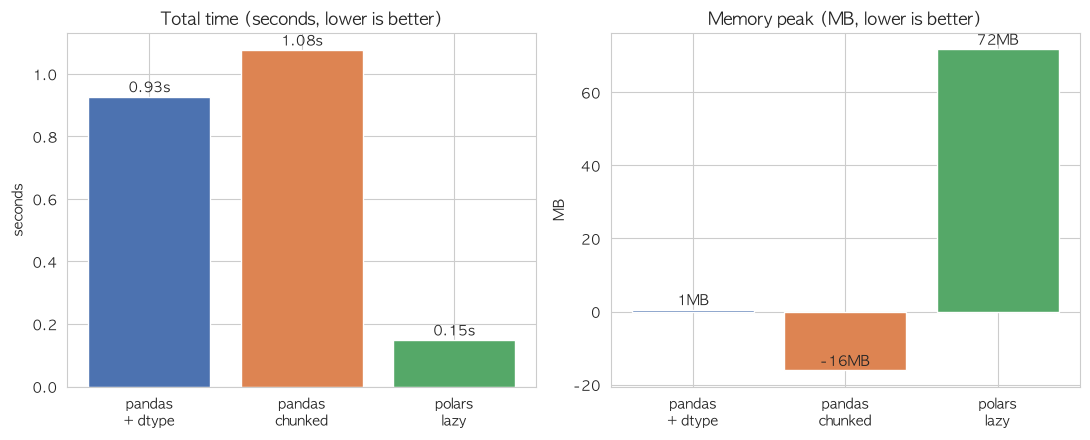

In [7]:
# ─────────────────────────────────────────────
# [도식] 세 가지 방식의 시간·메모리 비교
# ─────────────────────────────────────────────
methods = ["pandas\n+ dtype", "pandas\nchunked", "polars\nlazy"]
times = [elapsed_pd_full, elapsed_chunk_full, elapsed_pl_full]
peaks = [peak_pd_full, peak_chunk_full, peak_pl_full]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

bars0 = axes[0].bar(methods, times, color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Total time (seconds, lower is better)")
axes[0].set_ylabel("seconds")
for i, v in enumerate(times):
    axes[0].text(i, v, f"{v:.2f}s", ha="center", va="bottom")

bars1 = axes[1].bar(methods, peaks, color=["#4C72B0", "#DD8452", "#55A868"])
axes[1].set_title("Memory peak (MB, lower is better)")
axes[1].set_ylabel("MB")
for i, v in enumerate(peaks):
    axes[1].text(i, v, f"{v:.0f}MB", ha="center", va="bottom")

plt.tight_layout()
plt.show()

# 모두마켓 월간 로그 — 도구 선택 보고서

## 1. 데이터 개요
- 파일: web_logs.csv
- 크기: 32.3 MB, 500,000 행
- 주요 컬럼: ts / user_id / page / device / status_code / response_ms / bytes_sent



In [8]:
web_logs.columns

Index(['log_id', 'ts', 'user_id', 'session_id', 'page', 'device',
       'status_code', 'response_ms', 'bytes_sent'],
      dtype='str')

## 2. 측정 결과
| 방식 | 소요 시간 | 메모리 피크(증가량) |
|---|---|---|
| pandas + dtype | 0.93초 | 0.5MB |
| pandas chunked | 1.08초 | -16.1MB |
| Polars lazy    | 0.15초 | 71.8MB |


- `chunked`의 음수는 앞 단계 메모리가 해제되면서 생긴 측정 오차
- `Polars`는 내부 스레드 풀과 메모리 버퍼를 다음 작업에 쓰려고 붙잡아 두기 때문에 증가량이 크게 나옴
- 따라서 이번 비교는 **소요 시간**을 주된 근거로 삼음

## 3. 분석 결과 요약
- 페이지별 평균 응답 시간 최고: search (160.42 ms)
    - 모든 페이지가 158~160 ms, 중앙값 132~135 ms로 고르게 분포해서 특정 페이지의 병목은 보이지 않음
- 디바이스 점유율: mobile 69.9%, desktop 25.1%, tablet 4.9%
- 에러 1위 페이지:home (42,898건)
    - 이어서 list 35,593건, detail 28,298건 순이며, 트래픽이 많은 페이지에 에러가 몰리는 패턴
- 세 방식의 결과는 모두 같고, 표준편차만 chunked에서 소수점 둘째 자리 차이가 있음(search 113.81 vs 113.82)
- 단, 페이지별 에러율은 모두 28~29%로 비슷 → 에러 건수 차이는 트래픽 차이 때문 (전체 에러 142,757건, 28.6%)

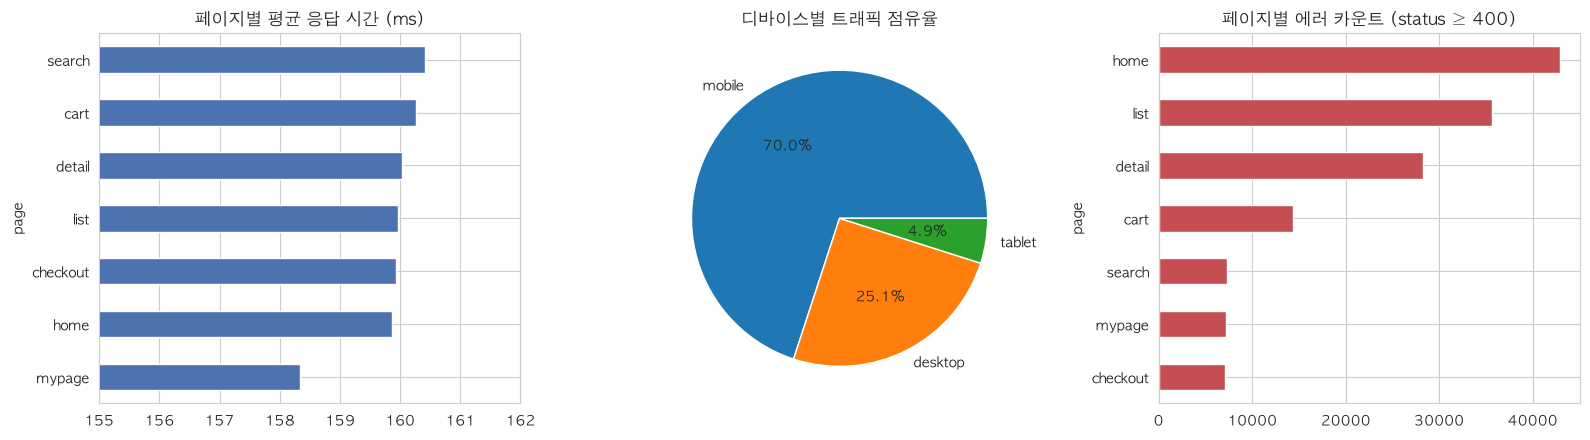

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

res_pl["by_page"]["mean"].sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("페이지별 평균 응답 시간 (ms)")
axes[0].set_xlim(155, 162)

res_pl["dev_share"].plot.pie(ax=axes[1], autopct="%.1f%%")
axes[1].set_title("디바이스별 트래픽 점유율")
axes[1].set_ylabel("")

res_pl["err_count"].sort_values().plot.barh(ax=axes[2], color="#C44E52")
axes[2].set_title("페이지별 에러 카운트 (status ≥ 400)")

plt.tight_layout()
plt.show()

## 4. 도구 선택 정당화 (한 단락)
이 분석에는 **Polars lazy**를 선택했습니다. (1) 측정 결과 0.15초로 pandas+dtype(0.93초)보다 약 6.2배 빨라 **가장 빨랐고**, 세 방식의 결과도 모두 같았습니다. (2) 팀 환경상 **매월 반복 실행하는 분석이라 재현성과 속도가 중요**하고, 동료들이 익숙한 pandas와는 `.to_pandas()`로 결과를 연결할 수 있습니다. (3) 청크 방식은 메모리를 아낄 수 있지만 중앙값·표준편차를 직접 누적 계산해야 해서 코드가 복잡하고, 이번 측정에서도 가장 느렸습니다(1.08초). Polars의 메모리 증가량(71.8 MB)은 가장 컸지만 평소 여유 메모리 약 6 GB의 약 1.2% 수준이라 문제가 되지 않습니다.

## 5. 다음 단계 제안
- 데이터 크기가 **약 2.7 GB(약 4,300만 행)** 까지 늘어나면 **Polars lazy + 청크 처리** 로 전환을 고려.
  - 이번 측정에서 Polars 메모리 증가량은 파일 크기의 약 2.2배(32.3 MB → 71.8 MB)
  - 분석에 쓸 수 있는 여유 메모리 약 6 GB ÷ 2.2배 ≈ 파일 약 2.7 GB까지 처리 가능
  - 행당 약 68바이트 기준으로 약 4,300만 행, 현재 월간 로그(50만 행)의 약 86개월분에 해당
  - 수업의 데이터 크기별 추천 표에서 1천만~1억 행 구간은 1차 선택이 Polars lazy, 메모리가 부족할 때 2차 선택이 청크 처리
  - 지금 쓰는 Polars lazy 파이프라인은 유지하고, 메모리 한계를 넘는 부분만 청크로 나눠 처리해 전환 비용 최소화
  - 단, 2.2배는 실행 전후 RSS 차이로 잰 추정치라 실제 피크는 더 높을 수 있음 → 전환 전 피크 메모리 재측정 필요
- 시각화·검증은 D+008에서 **Seaborn(분포·비교 차트)과 Plotly(에러 시계열)** 을 활용해 진행.

## 심화 1 — chunksize별 성능 비교

In [10]:
# 심화 1 — chunksize를 바꿔 시나리오 2 재측정
rows = []
for cs in [10_000, 50_000, 100_000, 200_000]:
    gc.collect()
    before = rss_mb()
    t0 = time.perf_counter()
    analyze_chunked(logs_csv, chunksize=cs)
    rows.append({
        "chunksize": f"{cs//1000}K",
        "청크 개수": -(-500_000 // cs),        # 올림 나눗셈
        "소요 시간(초)": round(time.perf_counter() - t0, 2),
        "메모리 증가량(MB)": round(rss_mb() - before, 1),
    })

chunk_result = pd.DataFrame(rows)
chunk_result

,chunksize,청크 개수,소요 시간(초),메모리 증가량(MB)
0,10K,50,1.53,3.3
1,50K,10,1.07,1.4
2,100K,5,0.94,5.8
3,200K,3,0.91,8.6


- 소요 시간: 10K 1.53초 → 50K 1.07초 → 100K 0.94초 → 200K 0.91초로, 청크가 클수록 빨라짐
  - 청크 개수가 50개 → 3개로 줄어, 반복할 때마다 드는 `read_csv`·`groupby` 비용이 감소
  - 10K → 50K 구간에서 0.46초 단축됐지만, 100K → 200K 구간은 0.03초 단축에 그쳐 일정 크기 이상에서는 효과가 거의 없음
- 메모리 증가량: 50K 1.4 MB → 100K 5.8 MB → 200K 8.6 MB로, 청크가 클수록 한 번에 올리는 데이터가 늘어 증가
  - 10K(3.3 MB)가 50K보다 높게 나온 것은 RSS 전후 차이 측정의 오차로 판단
- 가장 빠른 200K(0.91초)도 Polars lazy(0.15초)보다 약 6배 느림 → 도구 선택 결론은 그대로 유지

[결론] 청크 크기가 커질수록 속도는 빨라지고 메모리는 늘어나지만, 100K 이상에서는 속도 이득이 거의 없으므로 이 데이터에서는 **100K 전후가 속도와 메모리의 균형점**입니다.

## 심화 2 — Polars lazy .explain()

In [11]:
# 심화 2 — Polars lazy 실행 계획 확인
lf = pl.scan_csv(logs_csv, try_parse_dates=True)
err_plan = (
    lf.filter(pl.col("status_code") >= 400)
      .group_by("page")
      .agg(pl.len().alias("n_errors"))
      .sort("n_errors", descending=True)
)

print("=== 최적화 전 ===")
print(err_plan.explain(optimized=False))
print("\n=== 최적화 후 ===")
print(err_plan.explain())

=== 최적화 전 ===
SORT BY [descending: [true]] [col("n_errors")]
  AGGREGATE[maintain_order: false]
    [len().alias("n_errors")] BY [col("page")]
    FROM
    FILTER col("status_code") >= 400
    FROM
      Csv SCAN [moodumarket_big/web_logs.csv]
      PROJECT */9 COLUMNS
      ESTIMATED ROWS: 537956

=== 최적화 후 ===
SORT BY [descending: [true]] [col("n_errors")]
  AGGREGATE[maintain_order: false]
    [len().alias("n_errors")] BY [col("page")]
    FROM
    simple π 1/1 ["page"]
      Csv SCAN [moodumarket_big/web_logs.csv]
      PROJECT 2/9 COLUMNS
      SELECTION: col("status_code") >= 400
      ESTIMATED ROWS: 537956


- 최적화 전: `PROJECT */9 COLUMNS`로 9개 컬럼을 모두 읽은 뒤, 별도의 `FILTER` 단계에서 에러 행을 거름
- 최적화 후: 두 가지 최적화가 적용됨
  - **Projection pushdown**: `PROJECT 2/9 COLUMNS`로 계산에 필요한 `page`, `status_code` 2개 컬럼만 읽음
  - **Predicate pushdown**: `FILTER` 단계가 사라지고 `SELECTION: col("status_code") >= 400`으로 CSV를 읽는 단계에서 바로 에러 행만 남김
- 읽는 컬럼과 행이 모두 줄어, 4번 도구 선택 정당화에서 말한 "필요한 컬럼만 읽고 처리"가 실제 실행 계획으로 확인됨

[결론] Polars lazy는 실행 전에 계획을 최적화해 **필요한 2/9 컬럼만 읽고(projection pushdown), 필터를 읽기 단계로 내려(predicate pushdown)** 불필요한 데이터를 처음부터 읽지 않습니다.

## 심화 3 — Polars 도입 제안서

**[제안] 월간 로그 분석에 Polars lazy 단계적 도입**

동료 모두가 pandas를 쓰는 환경을 고려해, 전면 교체가 아니라 반복 실행되는 **대용량 집계**에만 `Polars lazy`를 도입할 것을 제안합니다. **학습 비용**은 group_by·agg·filter 등 pandas와 비슷한 문법이 많아 크지 않지만, lazy 실행(scan_csv → collect)과 표현식(pl.col) 방식에는 적응이 필요합니다. **기대 효과**는 이번 측정에서 같은 분석이 0.93초에서 0.15초로 약 6.2배 <u>빨라졌고</u>, 실행 계획상 필요한 컬럼만 읽고 필터를 먼저 적용해 <u>데이터가 커질수록 이점이 커진다</u>는 점입니다. 

**도입 단계**는 ① 월간 로그 집계 한 가지를 Polars로 바꾸고 결과를 .to_pandas()로 넘겨 <u>기존 pandas 시각화 코드를 그대로 사용</u> 
→ ② pandas 결과와 값이 같은지 <u>검증하고 소요 시간을 기록</u> → ③ 효과가 확인되면 다른 반복 작업으로 <u>범위를 넓히는 순서로 진행</u>합니다.